# Maximum-likelihood estimation of $\nu$ and $p$

This example fits the two parameters of the Housworth–Stahl model to a set of crossover positions:

- $\nu$, the interference parameter ($\nu = 1$ is no interference);
- $p$, the fraction of crossovers escaping interference.

It uses simulated data so the estimates can be compared with the truth. To use your own data,
replace the simulation step with a list holding one array of crossover positions (in Morgans) per
meiosis, and the chromosome length(s) `L`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.stats import chi2

from cointf import ChebyshevKernel, Meioses, loglik_fast, simulate_meioses

## Data

2,000 meioses of a 1.5 M chromosome, simulated with $\nu = 4$ and $p = 0.05$.

In [2]:
nu_true, p_true, L = 4.0, 0.05, 1.5
data = simulate_meioses(L=L, nu=nu_true, p=p_true, n=2000, seed=1)

counts = np.array([len(d) for d in data])
print(f"{len(data)} meioses, {counts.sum()} crossovers, mean {counts.mean():.2f} per meiosis")
print("first three:", [np.round(d, 3).tolist() for d in data[:3]])

2000 meioses, 3077 crossovers, mean 1.54 per meiosis
first three: [[], [0.519, 1.009, 1.451], [0.555]]


## Likelihood

`Meioses` validates the data and precomputes every distance once; each likelihood evaluation then
reuses it. `ChebyshevKernel` is optional: it makes repeated evaluations several times faster and
agrees with the exact kernel to about $10^{-12}$ in total log-likelihood here (checked below).

The optimiser works on $\theta = (\log \nu, \operatorname{logit} p)$, so every trial value is
in range.

In [3]:
mz = Meioses(data, L)
kernel = ChebyshevKernel()


def to_params(theta):
    return np.exp(theta[0]), 1.0 / (1.0 + np.exp(-theta[1]))


def negloglik(theta):
    nu, p = to_params(theta)
    return -loglik_fast(mz, None, nu=nu, p=p, kernel=kernel)

## Fit

Nelder–Mead needs no gradients and is robust for two parameters.

In [4]:
fit = minimize(negloglik, x0=[np.log(2.0), -2.0], method="Nelder-Mead",
               options=dict(xatol=1e-6, fatol=1e-8))
nu_hat, p_hat = to_params(fit.x)
ll_hat = -fit.fun
print(f"nu_hat = {nu_hat:.3f}   p_hat = {p_hat:.4f}   log-likelihood = {ll_hat:.3f}")
print(f"{fit.nfev} likelihood evaluations")

exact = loglik_fast(mz, None, nu=nu_hat, p=p_hat)
print(f"exact kernel at the MLE: {exact:.6f}  (difference {abs(exact - ll_hat):.1e})")

nu_hat = 3.773   p_hat = 0.0493   log-likelihood = -2698.526
109 likelihood evaluations
exact kernel at the MLE: -2698.526176  (difference 0.0e+00)


## Standard errors

The observed information is the Hessian of the negative log-likelihood at the MLE, computed here by
central finite differences on the $\theta$ scale. Wald intervals on that scale are mapped back to
$(\nu, p)$, so they stay in range.

In [5]:
def hessian(f, x, h=1e-3):
    x = np.asarray(x, dtype=float)
    k = x.size
    H = np.empty((k, k))
    E = np.eye(k) * h
    for i in range(k):
        for j in range(k):
            H[i, j] = (f(x + E[i] + E[j]) - f(x + E[i] - E[j])
                       - f(x - E[i] + E[j]) + f(x - E[i] - E[j])) / (4 * h * h)
    return H


cov = np.linalg.inv(hessian(negloglik, fit.x))
se = np.sqrt(np.diag(cov))
z = 1.96
lo, hi = to_params(fit.x - z * se), to_params(fit.x + z * se)
print(f"nu: {nu_hat:.2f}  95% CI [{lo[0]:.2f}, {hi[0]:.2f}]   (truth {nu_true})")
print(f"p:  {p_hat:.3f}  95% CI [{lo[1]:.3f}, {hi[1]:.3f}]   (truth {p_true})")
print(f"correlation of log nu and logit p: {cov[0, 1] / (se[0] * se[1]):.2f}")

nu: 3.77  95% CI [3.30, 4.31]   (truth 4.0)
p:  0.049  95% CI [0.029, 0.081]   (truth 0.05)
correlation of log nu and logit p: 0.52


## Likelihood surface

The log-likelihood relative to its maximum over a grid of $(\nu, p)$. The outlined region is the
95% joint confidence region (a drop of $\chi^2_{2, 0.95}/2 \approx 3.0$ log-likelihood units).
The region is tilted because the estimates of $\nu$ and $p$ are positively correlated: with more
escape crossovers absorbing the close pairs, the remaining interference crossovers must be more
regular, which means a larger $\nu$.

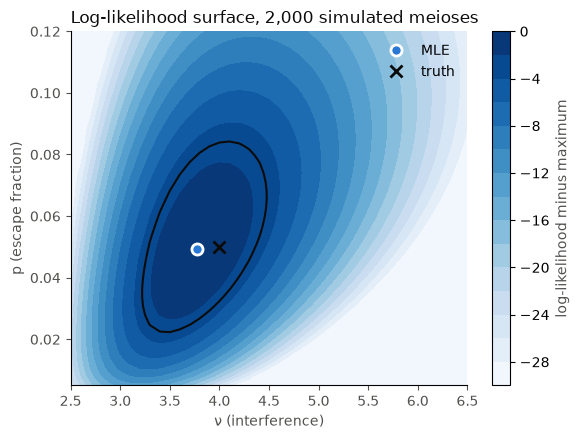

In [6]:
nus = np.linspace(2.5, 6.5, 41)
ps = np.linspace(0.005, 0.12, 41)
surface = np.array([[loglik_fast(mz, None, nu=a, p=b, kernel=kernel) for a in nus] for b in ps])
rel = surface - ll_hat

ink, ink2, grid, accent = "#0b0b0b", "#52514e", "#e1e0d9", "#2a78d6"
fig, ax = plt.subplots(figsize=(6.4, 4.6))
levels = np.arange(-30, 0.1, 2.0)
filled = ax.contourf(nus, ps, np.maximum(rel, -30), levels=levels, cmap="Blues")
ax.contour(nus, ps, rel, levels=[-chi2.ppf(0.95, 2) / 2], colors=ink, linewidths=1.5, linestyles="solid")
ax.plot(nu_hat, p_hat, "o", ms=8, color=accent, mec="white", mew=2, label="MLE")
ax.plot(nu_true, p_true, "x", ms=9, mew=2, color=ink, label="truth")
cbar = fig.colorbar(filled, ax=ax)
cbar.set_label("log-likelihood minus maximum", color=ink2)
ax.set_xlabel("ν (interference)", color=ink2)
ax.set_ylabel("p (escape fraction)", color=ink2)
ax.set_title("Log-likelihood surface, 2,000 simulated meioses", color=ink, loc="left")
ax.legend(frameon=False, loc="upper right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=ink2)
plt.show()

## Profile likelihood for $\nu$

For each $\nu$, maximise over $p$. The interval where the profile is within
$\chi^2_{1, 0.95}/2 \approx 1.92$ of its maximum is a 95% profile-likelihood interval. It does
not rely on the quadratic approximation behind the Wald interval, so the two can be compared.

95% profile interval for nu: about [3.40, 4.30] (grid step 0.1)


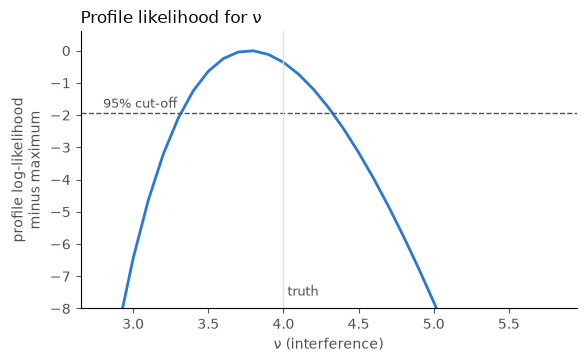

In [7]:
def profile(nu):
    res = minimize(lambda t: -loglik_fast(mz, None, nu=nu, p=1 / (1 + np.exp(-t[0])), kernel=kernel),
                   x0=[fit.x[1]], method="Nelder-Mead", options=dict(xatol=1e-6, fatol=1e-8))
    return -res.fun


grid_nu = np.linspace(2.8, 5.8, 31)
prof = np.array([profile(v) for v in grid_nu]) - ll_hat
cut = -chi2.ppf(0.95, 1) / 2
inside = grid_nu[prof >= cut]
print(f"95% profile interval for nu: about [{inside.min():.2f}, {inside.max():.2f}] (grid step 0.1)")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(grid_nu, prof, color=accent, lw=2)
ax.axhline(cut, color=ink2, lw=1, ls="--")
ax.text(grid_nu[0], cut + 0.15, "95% cut-off", color=ink2, fontsize=9)
ax.axvline(nu_true, color=grid, lw=1)
ax.text(nu_true, -7.6, " truth", color=ink2, fontsize=9)
ax.set_xlabel("ν (interference)", color=ink2)
ax.set_ylabel("profile log-likelihood\nminus maximum", color=ink2)
ax.set_title("Profile likelihood for ν", color=ink, loc="left")
ax.set_ylim(-8, 0.6)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=ink2)
plt.show()

## Notes

- **Per-meiosis parameters.** `nu` and `p` may also be arrays with one value per meiosis, for
  example `nu = np.exp(b0 + b1 * age)`. The same recipe then fits regression coefficients. With
  many distinct `nu` values the Chebyshev kernel falls back to the exact series.
- **Phase-unknown data.** For pooled crossovers from two meioses, replace `loglik_fast` with
  `loglik_quartet`; nothing else changes.
- **Coordinates.** Use genetic-map positions in Morgans. Physical positions would confound
  recombination hotspots with interference.